# Stroke Prediction Dataset 

* Data Visualization & Preprocessing Assignment:

## Part 1 — Data Loading & Initial Inspection

In [1]:
# 1. Import important libraries (pandas, numpy, matplotlib, seaborn, sklearn).
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from imblearn.over_sampling import RandomOverSampler

sns.set_theme(style="whitegrid") 


print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# 2. Load healthcare-dataset-stroke-data.csv into DataFrame df
df = pd.read_csv("healthcare-dataset-stroke-data.csv")
print("Dataset is read successfully!")


Dataset is read successfully!


In [3]:
# 3. Display first 5 rows using df.head()
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [4]:
# 4. Use df.info() to check data types, non-null values, memory usage
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [5]:
# 5. Use df.describe() for statistical summaries
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


 — After the initial inspection

The dataset contains 5,110 patient records and 12 columns. The target, stroke, is coded as 0 for no recorded stroke and 1 for recorded stroke. BMI was the only column with missing values, so it was the focus of the missing-data check.

## Part 2 — Exploratory Data Analysis & Visualization


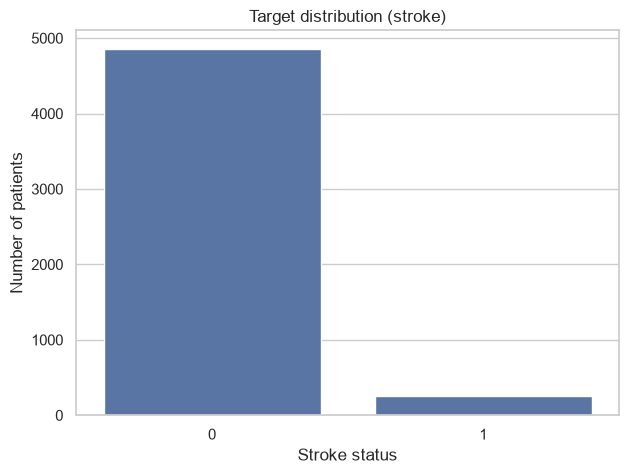

In [6]:
# 1. Create countplot for stroke column (class distribution)
plt.figure(figsize=(7, 5))

sns.countplot(x="stroke", data=df)

plt.title("Target distribution (stroke)")
plt.xlabel("Stroke status")
plt.ylabel("Number of patients")

plt.show()

In [7]:
# Number of patients in each stroke category
print(df['stroke'].value_counts())

# Percentage of patients in each category
print(df['stroke'].value_counts(normalize=True) * 100)


stroke
0    4861
1     249
Name: count, dtype: int64
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


Only 4.87% of the original records were stroke cases. This imbalance is the reason I stratified the split and later resampled the training set.

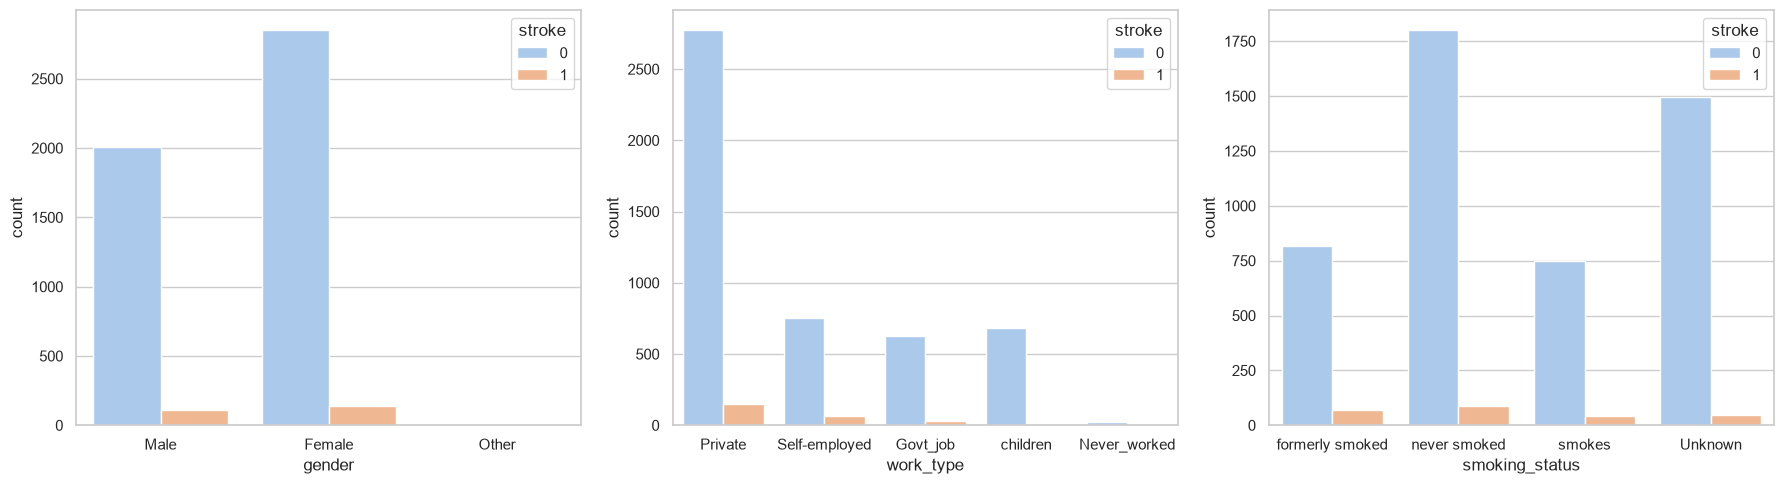

In [8]:
# 2. Create countplots with hue='stroke' for gender, work_type, smoking_status using subplots
cols = ['gender','work_type','smoking_status']

fig, axes = plt.subplots(1,3, figsize=(18,5))

for ax, col in zip(axes,cols):
    sns.countplot(data=df, x=col, hue='stroke', ax=ax, palette='pastel')


# Adjust spacing between plots
plt.tight_layout( )
plt.show()

The grouped plots show counts. To compare groups of different sizes, I divided stroke cases by the total in each group. The female group had more recorded cases (141 versus 108), while the male group had a slightly higher observed stroke proportion in this sample (5.11% versus 4.71%).

In [9]:
# Check gender categories before cleaning
print(df["gender"].value_counts())

# Remove the 'Other' category
df = df[df["gender"] != "Other"].copy() 

# Reset the index
df.reset_index(drop=True, inplace=True)

# Verify the result
print(df["gender"].value_counts())
print("New dataset shape:", df.shape)

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
gender
Female    2994
Male      2115
Name: count, dtype: int64
New dataset shape: (5109, 12)


I removed the single record with gender labeled Other, as required by the assignment. The dataset went from 5,110 to 5,109 rows, and the gender column was kept.

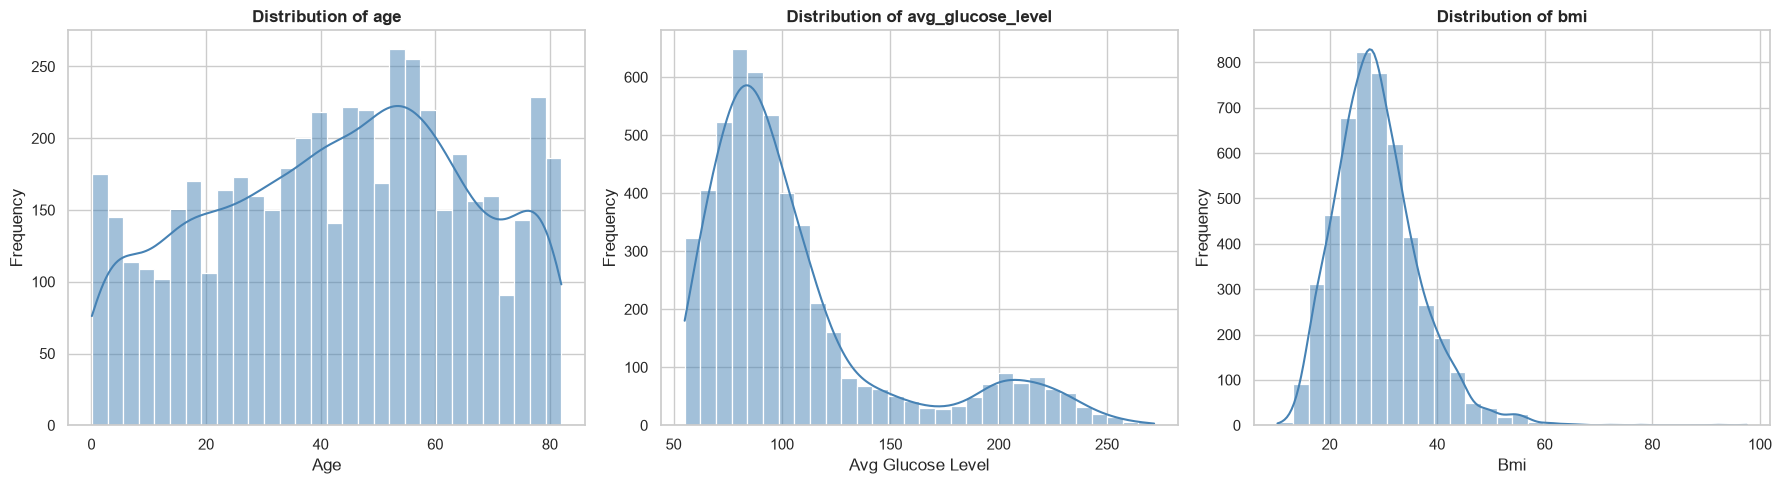

In [10]:
# 4. Create histograms/KDE plots for age, avg_glucose_level, bmi using subplots
cols = ['age', 'avg_glucose_level', 'bmi']


fig, axes = plt.subplots(1,3, figsize=(18,5))

for i, col in enumerate(cols):
    sns.histplot(data = df,
                x=col,
                kde=True,
                ax=axes[i],
                color="steelblue",
                bins= 30)
    axes[i].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col.replace('_', ' ').title())
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

The glucose and BMI distributions have long right tails. I used this information when choosing a BMI fill value and reviewing the high glucose readings in Part 3.

In [11]:
num_cols = df.select_dtypes(include=['number'])
print(num_cols.columns)

Index(['id', 'age', 'hypertension', 'heart_disease', 'avg_glucose_level',
       'bmi', 'stroke'],
      dtype='str')


In [12]:
num_cols = df.select_dtypes(include=['number']).drop(columns=['id'])
print(num_cols.columns)

Index(['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi',
       'stroke'],
      dtype='str')


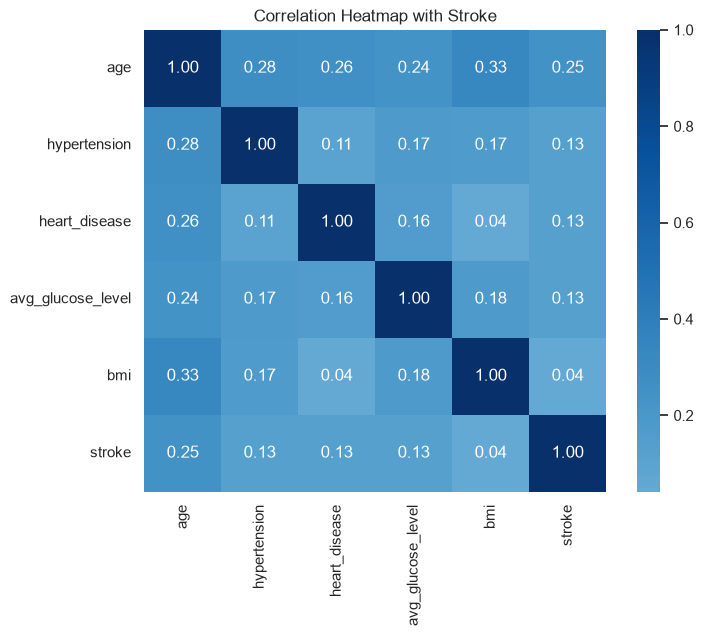

In [14]:
# 5. Create correlation heatmap using selected numerical features and stroke
plt.figure(figsize=(8, 6))
sns.heatmap(num_cols.corr(), annot=True, fmt=".2f", cmap="Blues", center=0, square=True)
plt.title("Correlation Heatmap with Stroke")
plt.show()

Age had the strongest correlation with recorded stroke among the features shown (r = 0.25). Average glucose, hypertension, and heart disease each had a smaller positive correlation of about 0.13. These pairwise results describe associations in this sample.

## Part 3 — Data Preprocessing


In [15]:
# 1. Check for missing values using df.isnull().sum() 
print("\nMissing values:")
df.isnull().sum()


Missing values:


id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

I filled 201 missing BMI values with the median because BMI has a long right tail and the median is less sensitive to extreme values. The assignment places this step before the split. For a future model evaluation, I would calculate the median on the training set and apply it to both sets.

In [16]:
# 2. Fill bmi missing values using mean or median 
df["bmi"] = df["bmi"].fillna(df["bmi"].median())

In [17]:
# 3. Verify no missing values remain
df.isnull().sum()

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [18]:
# 4. Check for duplicates and remove them if any exist
df.duplicated().sum()

np.int64(0)

In [19]:
# 5. Drop id column (no predictive power)
df = df.drop(columns=['id'])

# Verifying it has been removed
print(df.columns)


Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')


The exact-duplicate check found zero rows to remove. I excluded id from the features because it identifies a record.

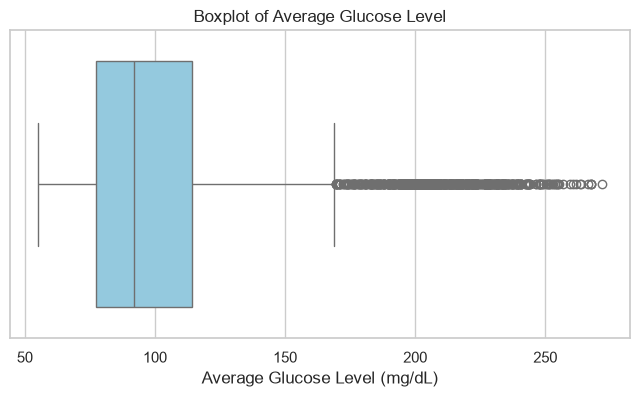

In [20]:
# 6. Create boxplot for avg_glucose_level to detect outliers and remove if needed
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['avg_glucose_level'], color='skyblue')
plt.title('Boxplot of Average Glucose Level')
plt.xlabel('Average Glucose Level (mg/dL)')
plt.show()

I used the default 1.5 × IQR rule for the boxplot. It flagged 627 readings above the upper fence of about 169.37 mg/dL and none below the lower fence. I retained the flagged readings because high glucose can be genuine and the boxplot alone gave me insufficient evidence of a recording error.

## Part 4 — Feature Transformation

In [21]:
#1. Encode categorical variables: gender, work_type, smoking_status, ever_married, Residence_type 

# Define the categorical columns to encode

cat_cols=[
    "gender",
    "work_type",
    "smoking_status",
    "ever_married",
    "Residence_type"
]

# 2. Reset DataFrame index 
df = df.reset_index(drop=True)


# 3. Apply one-hot encoding using pd.get_dummies() or OneHotEncoder
df_encoded = pd.get_dummies(df, columns= cat_cols,  dtype=int)

In [22]:
print("Before encoding", df.shape)
print("After encoding", df_encoded.shape)

Before encoding (5109, 11)
After encoding (5109, 21)


In [23]:
print("Index is sequential:", df_encoded.index.equals(pd.RangeIndex(len(df_encoded))))
print("Stroke values preserved:", df_encoded["stroke"].equals(df["stroke"].reset_index(drop=True)))

Index is sequential: True
Stroke values preserved: True


One-hot encoding replaced five categorical columns with 15 binary indicators. The 5,109 rows and their stroke labels were preserved, and the index check confirmed a sequential index.

## Part 5 — Data Splitting

In [24]:
#1. Separate features X and target y
x = df_encoded.drop(columns=["stroke"])
y = df_encoded["stroke"]

In [25]:
# 2. Use train_test_split() with 80/20 ratio and random_state=42 
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

In [26]:
# 3. Verify shapes of x_train, x_test, y_train, y_test

print("Train:", x_train.shape, "| Test:", x_test.shape)
print("Train:",  y_train.shape, "   | Test:", y_test.shape)


Train: (4087, 20) | Test: (1022, 20)
Train: (4087,)    | Test: (1022,)


The stratified 80/20 split produced 4,087 training records and 1,022 test records. Stratification kept the stroke proportion close to 4.9% in each set.

## Part 6 — Feature Scaling

In [27]:
# 1. Import StandardScaler or MinMaxScaler 

# * Imported already in part one ^^

In [28]:
# 2. Scale numerical features: age, avg_glucose_level, bmi 
scale_cols = ["age","avg_glucose_level","bmi"]

scaler = StandardScaler()
x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()


In [29]:
# 3. Fit scaler on training data only, then transform both train and test sets

x_train_scaled[scale_cols] = scaler.fit_transform(x_train[scale_cols])
x_test_scaled[scale_cols] = scaler.transform(x_test[scale_cols])

x_train_scaled[scale_cols].describe().loc[["mean", "std", "min", "max"]].round(2)

,age,avg_glucose_level,bmi
mean,-0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-1.91,-1.13,-2.40
max,1.71,3.71,8.89


In [30]:
print("Train shape", x_train_scaled.shape)
print("Test shape", x_test_scaled.shape)

print(x_train_scaled[scale_cols].mean().round(6))
print(x_train_scaled[scale_cols].std(ddof=0).round(6))

Train shape (4087, 20)
Test shape (1022, 20)
age                 -0.0
avg_glucose_level    0.0
bmi                 -0.0
dtype: float64
age                  1.0
avg_glucose_level    1.0
bmi                  1.0
dtype: float64


I fitted the scaler on training values for age, average glucose, and BMI, then applied the same transformation to the test set. The scaled training columns have means near zero and standard deviations near one.

## Part 7 — Handling Class Imbalance

In [31]:
# 1. Check distribution of stroke 
print(y_train.value_counts().sort_index())

stroke
0    3888
1     199
Name: count, dtype: int64


In [32]:
# 2. Apply oversampling/undersampling or SMOTE 
ros = RandomOverSampler(random_state=42)
x_train_resampled, y_train_resampled = ros.fit_resample(x_train_scaled, y_train)


In [33]:
# 3. Verify balanced distribution
print(y_train_resampled.value_counts().sort_index())
print("Resampled feature shape", x_train_resampled.shape)
print("Resampled target shape", y_train_resampled.shape)

stroke
0    3888
1    3888
Name: count, dtype: int64
Resampled feature shape (7776, 20)
Resampled target shape (7776,)


Random oversampling reused training rows from the minority class, increasing stroke examples from 199 to 3,888 and matching the 3,888 non-stroke examples. The test set stayed at 972 non-stroke and 50 stroke records.

# Conclusion

In [21]:
df.groupby("stroke")[["age", "avg_glucose_level"]].mean().round(2)

,age,avg_glucose_level
stroke,,
0,41.97,104.79
1,67.73,132.54


In the original dataset, 249 of 5,110 records (4.87%) had a recorded stroke. In the cleaned data, the stroke group averaged 67.7 years of age and 132.5 mg/dL in average glucose, compared with 42.0 years and 104.8 mg/dL in the group without a recorded stroke. Hypertension and heart disease also showed positive associations with recorded stroke.

Illustrative higher-risk patient profile. A 68-year-old patient with hypertension, a history of heart disease, and an average glucose level of about 133 mg/dL reflects several patterns observed in the stroke group. The age and glucose values are rounded group averages. This fictional profile summarizes the exploratory findings and cannot estimate an individual’s stroke risk.

The final dataset had 20 features. Random oversampling balanced the training set, while the test set retained the original class proportions for future evaluation. An all-no-stroke prediction would be right for about 95% of the original records and would miss every recorded stroke case. That is why I would report stroke recall and precision alongside accuracy in a future model evaluation.